# ERA5 Peru: local-day TX90, TN90 and joint heatwaves

Registered ERA5 daily 1991–2025, reference 1991–2020; a four-day hourly subset demonstrates aggregation. Period-ending mx2t/mn2t use offset:-05:00. Air above land and ocean remains atmospheric temperature. Real AHW summaries are reproduced outputs pending scientific review.

Read [the tutorial guide](../docs/TUTORIALS.md) for inputs, units and configuration. Saved outputs can be read without data. Re-execution requires the optional `examples/requirements.txt` and, for real cases, the inputs in [Data](../docs/DATA.md). No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 15 / None |
| Percentile estimator | hyndman_fan_8 |
| Minimum samples | 360 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 3 / 0 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | offset:-05:00 |
| Support / spatial dimensions | surface / latitude, longitude |
| Domain / measure | air_over_land / area |
| Review status | executed; real AHW summaries pending scientific review |

The representative definition is supplemented by the explicitly shown MCS/dynamic or TX/TN joint comparisons where present. Tracking configuration appears in its recipe cell. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/era5.json).


In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "era5"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from pathlib import Path

import numpy as np
from _data import era5_profiles, hourly_era5, load_era5, record, surface_grid
from _report import temporal_summary, write_report
from plotting import frequency_figure, pyplot, save_figure

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Load the registered daily analysis and a short hourly demonstration

The full daily dataset drives the baseline. Only four days of the registered 2023 hourly file are materialized for a boundary-aware demonstration.

In [4]:
daily, baseline = load_era5(data_dir)
hourly = hourly_era5(data_dir)
print("ERA5 Peru 1991–2025; reference 1991–2020; offset:-05:00; SHA-256 verified.")

ERA5 Peru 1991–2025; reference 1991–2020; offset:-05:00; SHA-256 verified.


## Hourly period-ending extrema belong to the day of their interval start

UTC period-ending timestamps are shifted to their interval starts before assigning offset:-05:00 days. All 24 observations are required. The three complete interior days must match the registered daily TX/TN exactly. Sampled t2m is only a contrast.

plotting.py:72: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.savefig(output_dir / f"{name}.png", dpi=150, bbox_inches="tight")


,tx,tx_n_samples,latitude,longitude
time,,,,
2023-02-28,NaN,6,-7.75,-79.5
2023-03-01,298.581543,24,-7.75,-79.5
2023-03-02,297.978271,24,-7.75,-79.5
2023-03-03,297.901367,24,-7.75,-79.5
2023-03-04,NaN,18,-7.75,-79.5


events.py:101: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


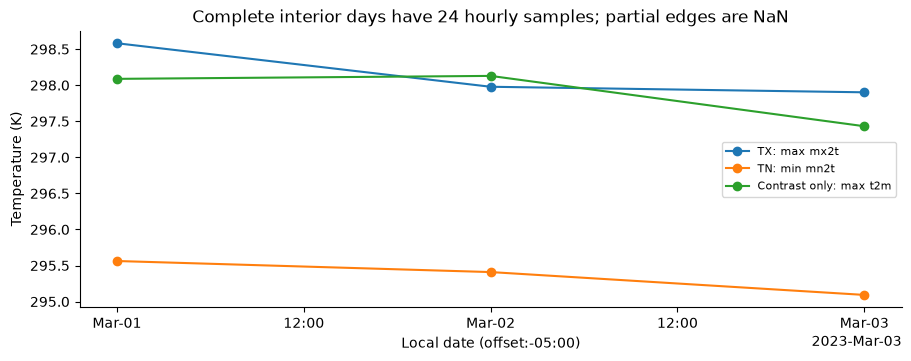

In [5]:
tx = xhw.aggregate_daily(
    hourly,
    variable="mx2t",
    statistic="max",
    sampling="period_ending",
    input_clock="UTC",
    day_definition="offset:-05:00",
    name="tx",
)
tn = xhw.aggregate_daily(
    hourly,
    variable="mn2t",
    statistic="min",
    sampling="period_ending",
    input_clock="UTC",
    day_definition="offset:-05:00",
    name="tn",
)
contrast = xhw.aggregate_daily(
    hourly,
    variable="t2m",
    statistic="max",
    sampling="instantaneous",
    input_clock="UTC",
    day_definition="offset:-05:00",
    name="tx_t2m",
)
interior = slice("2023-03-01", "2023-03-03")
errors = {}
for name, aggregated in (("tx", tx), ("tn", tn)):
    a, b = aggregated[name].sel(time=interior), daily[name].sel(time=interior)
    np.testing.assert_allclose(a, b, rtol=0, atol=0, equal_nan=True)
    errors[name] = 0.0
plt = pyplot()
figure, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
for values, label in (
    (tx.tx, "TX: max mx2t"),
    (tn.tn, "TN: min mn2t"),
    (contrast.tx_t2m, "Contrast only: max t2m"),
):
    ax.plot(values.time, values.isel(latitude=15, longitude=10), "o-", label=label)
ax.set(
    ylabel="Temperature (K)",
    xlabel="Local date (offset:-05:00)",
    title="Complete interior days have 24 hourly samples; partial edges are NaN",
)
ax.legend(fontsize=8)
figure = save_figure(figure, output_dir, "aggregation")

tx[["tx", "tx_n_samples"]].isel(latitude=15, longitude=10).to_dataframe()

**Reading these figures.** The hourly aggregation curve is temperature in K on local UTC−05:00 dates. TX/TN use period-ending mx2t/mn2t, while sampled t2m is a contrast with instantaneous sampling. Partial boundary days are missing; the table records sample counts.

## Define complementary air domains; neither is volumetric ocean temperature

Land is lsm ≥0.5; ocean is lsm <0.5, intersected with available support. Keep atmosphere and volumetric seawater interpretations separate.

In [6]:
grids = {
    domain: surface_grid(
        lat="latitude",
        lon="longitude",
        domain=domain,
        domain_mask=mask,
        product="ERA5 single levels",
        resolution="0.25 degree",
    )
    for domain, mask in (("air_over_land", "land_mask"), ("air_over_ocean", "ocean_mask"))
}
profiles = era5_profiles()
metrics, masks = {}, {}

## Fit and detect each profile; combine daily TX and TN before testing persistence

BaselineResult separates reference, threshold and sample diagnostics. Detection then produces XMask evidence, and the temporal catalog stores cell-level events.

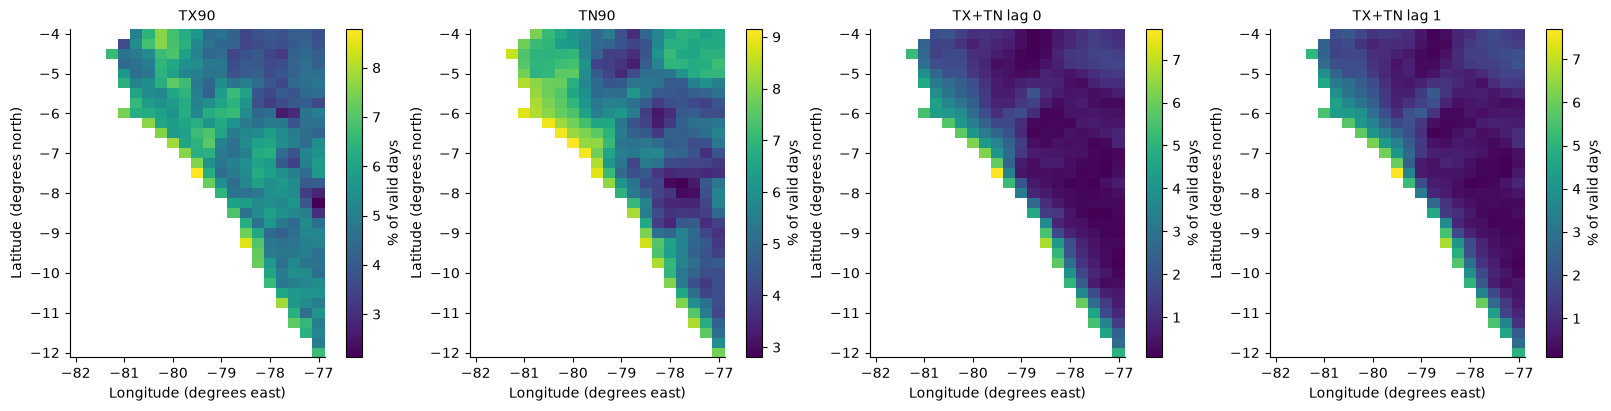

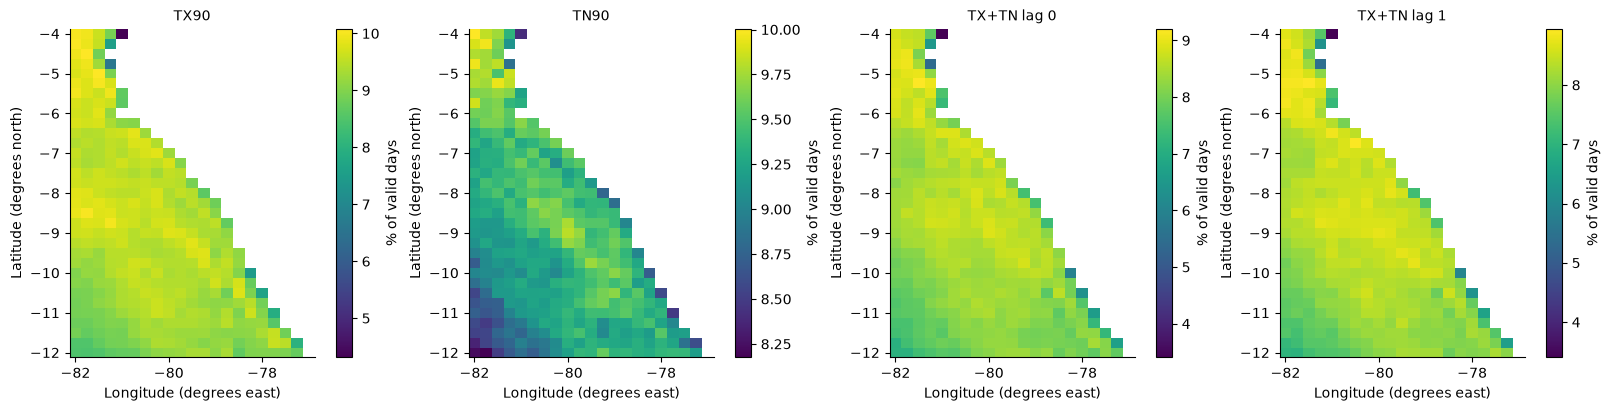

In [7]:
for domain, grid in grids.items():
    grid.check(daily)
    metrics[domain], masks[domain] = {}, {}
    for profile, (definition, variable) in profiles.items():
        fitted = xhw.fit_baseline(
            daily, variable=variable, grid=grid, baseline=baseline, definition=definition
        )
        fitted.check_invariants()
        mask = xhw.detect(
            daily, variable=variable, grid=grid, definition=definition, baseline_result=fitted
        )
        mask.check_invariants()
        catalog = xhw.build_catalog(mask, analysis_mode="retrospective")
        catalog.check_against(mask)
        masks[domain][profile] = mask
        metrics[domain][profile] = temporal_summary(mask, catalog)
    figure = frequency_figure(masks[domain], output_dir, name=domain)

**Reading these figures.** Frequency maps show the percentage of occupied valid days, with both numerator and denominator restricted to valid support. Outside-domain cells are blank. Panels have individual scales; compare colorbar values rather than color alone. Differences between methods/profiles are not proof of greater scientific skill.

## Report profile definitions and the verified hourly-to-daily agreement

All component and domain specifications and hourly agreement are recorded. The saved tables below are from this execution, not illustrative output.

In [8]:
grid = grids["air_over_land"]
definition = profiles["TX90"][0]
metrics["aggregation_max_absolute_difference_K"] = errors
report = write_report(
    output_dir,
    "era5",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=definition,
    review="executed; real AHW summaries pending scientific review",
    extra={
        "selection": "Peru -12 to -4 degrees north, -82 to -77 east; 1991–2025",
        "domains": {k: v.to_dict() for k, v in grids.items()},
        "profiles": {k: v[0].to_dict() for k, v in profiles.items()},
        "hourly_demonstration": "2023-03-01 to 2023-03-04 UTC; 24 samples/day",
        "hourly_sha256": record("era5")["hourly_files_sha256"]["2023.nc"],
        "aggregation_counts": tx.tx_n_samples.isel(latitude=15, longitude=10).values.tolist(),
    },
)

{
  "air_over_land": {
    "TX90": {
      "events": 43506,
      "exceedance_cell_days": 465586,
      "event_cell_days": 214209,
      "joined_cell_days": 0,
      "valid_cell_days": 4129232,
      "filled_cell_days": 0,
      "max_duration_days": 346
    },
    "TN90": {
      "events": 41252,
      "exceedance_cell_days": 478502,
      "event_cell_days": 231231,
      "joined_cell_days": 0,
      "valid_cell_days": 4129232,
      "filled_cell_days": 0,
      "max_duration_days": 407
    },
    "TX+TN lag 0": {
      "events": 8921,
      "exceedance_cell_days": 126816,
      "event_cell_days": 57658,
      "joined_cell_days": 0,
      "valid_cell_days": 4129232,
      "filled_cell_days": 0,
      "max_duration_days": 345
    },
    "TX+TN lag 1": {
      "events": 9941,
      "exceedance_cell_days": 149866,
      "event_cell_days": 61441,
      "joined_cell_days": 0,
      "valid_cell_days": 4128909,
      "filled_cell_days": 0,
      "max_duration_days": 346
    }
  },
  "air_over

## Interpretation and provenance

Inspect the executed report and [metrics guide](https://github.com/DanielCamarena/xhw/blob/main/docs/METRICS.md). Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. Figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [9]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; real AHW summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:74c7aa86ab6eb83273d02a3b942f16a87d00c8af81457837c5a54e31339caa60'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [10]:
from exploration import explorer

cases = {f"{domain}: {profile}": (mask, None, None)
         for domain, products in masks.items() for profile, mask in products.items()}
explorer(cases)
